# Detecção de amastigotas fora do macrófago

- Autor: Clésio Gonçalves
- Data: 21 jun. 2026
- Esse algoritmo utiliza os recortes (512x512) de macrófagos infectados para treinar um detector de classe única (YOLOv11 nano) de leishmania **fora** do macrófago, ignorando as anotações de macrófago e de leishmania dentro do macrófago (*inside-macrophage*).
- Validação por **6 folds** (5 lâminas treino / 1 validação / 2 teste por fold, ver `divisao_dataset.jpeg`), com diagnóstico agregado por fold e também por lâmina individual.

## Resultados (primeira rodada)

Treinamento local na GPU (RTX 5070 Ti), `yolo11n`, `imgsz=512`, `epochs=100` com `patience=30` (todos os folds convergiram por early stopping entre 45 e 100 épocas).

**Métricas globais — média ± desvio padrão entre os 6 folds:**

| Métrica | Média | Desvio padrão |
|---|---|---|
| Precisão | 0.473 | 0.116 |
| Recall | 0.501 | 0.078 |
| mAP50 | 0.439 | 0.123 |
| mAP50-95 | 0.169 | 0.046 |

**Por lâmina (mAP50):** melhor desempenho em `leish_7` (0.629) e `leish_5` (0.523); pior em `leish_4` (0.173) e `leish_3` (0.256) — ambas com poucas instâncias de leishmania fora do macrófago no dataset original (132 e 10, respectivamente).

Valores modestos para uma primeira rodada, como esperado. Próximos passos para melhorar: mais épocas/ajuste de hiperparâmetros, data augmentation específico, e investigar possíveis inconsistências de anotação em `leish_3`/`leish_4`.

## Utilização da GPU

In [1]:
!nvidia-smi

Tue Jun 23 01:38:01 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 595.71.05              Driver Version: 595.71.05      CUDA Version: 13.2     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 5070 Ti     Off |   00000000:01:00.0 Off |                  N/A |
|  0%   38C    P8             16W /  300W |      15MiB /  16303MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
import os
os.environ["CUDA_DEVICE_ORDER"]="PCI_BUS_ID"
os.environ["CUDA_VISIBLE_DEVICES"]="0"

# Importações e parâmetros gerais

In [3]:
import shutil
import yaml
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from ultralytics import YOLO

import warnings
warnings.filterwarnings('ignore')

# Bloqueia logs de C++ (INFO e WARNING)
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3' 
os.environ['TF_MLIR_ENABLE_MLIR_HAL_TARGET_ EXECUTABLE_DUMP_PATH'] = ''
os.environ['MLIR_CRASH_REPRODUCER_DIRECTORY'] = ''

In [4]:
# Versões dos pacotes usados neste jupyter notebook
%reload_ext watermark
%watermark -a "Clésio Gonçalves" --iversions
!python --version
!conda -V

Author: Clésio Gonçalves

matplotlib : 3.10.6
numpy      : 2.3.5
pandas     : 2.3.3
ultralytics: 8.4.75
yaml       : 6.0.3

Python 3.13.9


conda 26.1.1


In [5]:
import torch
torch.cuda.is_available()

True

## Parâmetros do sistema

In [6]:
# Diretório raiz
diretorio_raiz = Path("/mnt/arquivos/Doutorado")

## Estrutura do Dataset (sugerido por Rafael)

PROBLEMA:
  - 8 lâminas anotadas no formato YOLO
  - Classes originais:
      0 - Non-macrophage
      1 - Macrophage
      2 - leishmania (FORA do macrófago) --> classe de interesse
      3 - Inside-macrophage (leishmania DENTRO do macrófago) --> IGNORADA
 
  - Objetivo: detectar APENAS leishmania fora dos macrófagos (classe 2)

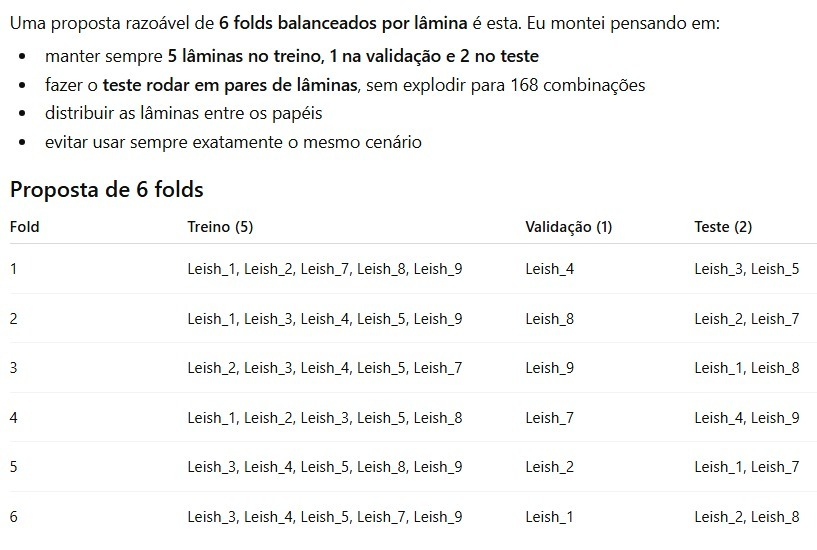

## Parâmetros do experimento

In [7]:
# Diretório com os recortes (512x512) de macrófagos infectados, organizados por lâmina
diretorio_recortes = os.path.join(diretorio_raiz, "dataset_recortes_macrofagos_infectados")

# Tamanho de entrada da rede = tamanho original do recorte (sem redimensionar)
tamanho_imagem = 512
extensao = '.png'

# Classes do dataset de recortes (mesma ordem do obj.names)
caminho_obj_names = os.path.join(diretorio_recortes, "obj.names")
with open(caminho_obj_names) as f:
    classes_originais = [linha.strip() for linha in f]

# Apenas leishmania FORA do macrófago é a classe de interesse (single-class detector)
nome_classe_interesse = 'leishmania'
indice_classe_interesse = classes_originais.index(nome_classe_interesse)
print(f"Classes originais: {classes_originais}")
print(f"Índice de '{nome_classe_interesse}' (classe de interesse): {indice_classe_interesse}")

# Diretórios de trabalho
diretorio_yolo_folds = os.path.join(diretorio_raiz, "yolo_folds_leishmania")
diretorio_runs = os.path.join(diretorio_raiz, "runs_leishmania_kfold")
os.makedirs(diretorio_yolo_folds, exist_ok=True)
os.makedirs(diretorio_runs, exist_ok=True)

# Hiperparâmetros de treinamento (primeira rodada; ajustar depois conforme métricas)
parametros_treino = dict(
    epochs=100,
    patience=30,
    imgsz=tamanho_imagem,
    batch=16,
    device=0,
    seed=42,
    workers=8,
    verbose=False,
)

Classes originais: ['Non-macrophages', 'macrophage', 'leishmania', 'inside-macrophage']
Índice de 'leishmania' (classe de interesse): 2


## Definição dos 6 folds (treino / validação / teste) por lâmina

Divisão balanceada proposta: 5 lâminas no treino, 1 na validação e 2 no teste (em pares), conforme `divisao_dataset.jpeg`.

In [8]:
folds = [
    {'fold': 1, 'treino': ['leish_1', 'leish_2', 'leish_7', 'leish_8', 'leish_9'], 'validacao': ['leish_4'], 'teste': ['leish_3', 'leish_5']},
    {'fold': 2, 'treino': ['leish_1', 'leish_3', 'leish_4', 'leish_5', 'leish_9'], 'validacao': ['leish_8'], 'teste': ['leish_2', 'leish_7']},
    {'fold': 3, 'treino': ['leish_2', 'leish_3', 'leish_4', 'leish_5', 'leish_7'], 'validacao': ['leish_9'], 'teste': ['leish_1', 'leish_8']},
    {'fold': 4, 'treino': ['leish_1', 'leish_2', 'leish_3', 'leish_5', 'leish_8'], 'validacao': ['leish_7'], 'teste': ['leish_4', 'leish_9']},
    {'fold': 5, 'treino': ['leish_3', 'leish_4', 'leish_5', 'leish_8', 'leish_9'], 'validacao': ['leish_2'], 'teste': ['leish_1', 'leish_7']},
    {'fold': 6, 'treino': ['leish_3', 'leish_4', 'leish_5', 'leish_7', 'leish_9'], 'validacao': ['leish_1'], 'teste': ['leish_2', 'leish_8']},
]

pd.DataFrame(folds).set_index('fold')

,treino,validacao,teste
fold,,,
1,"[leish_1, leish_2, leish_7, leish_8, leish_9]",[leish_4],"[leish_3, leish_5]"
2,"[leish_1, leish_3, leish_4, leish_5, leish_9]",[leish_8],"[leish_2, leish_7]"
3,"[leish_2, leish_3, leish_4, leish_5, leish_7]",[leish_9],"[leish_1, leish_8]"
4,"[leish_1, leish_2, leish_3, leish_5, leish_8]",[leish_7],"[leish_4, leish_9]"
5,"[leish_3, leish_4, leish_5, leish_8, leish_9]",[leish_2],"[leish_1, leish_7]"
6,"[leish_3, leish_4, leish_5, leish_7, leish_9]",[leish_1],"[leish_2, leish_8]"


## Construção da estrutura de dataset YOLO para cada fold

Para cada fold, as imagens são apenas referenciadas (link simbólico) a partir dos recortes originais — sem duplicar dados em disco. Os `.txt` de anotação são reescritos contendo **apenas a classe `leishmania`**, remapeada para o índice `0` (detector de classe única). As lâminas de teste também são organizadas em subpastas individuais, para permitir o diagnóstico por lâmina.

In [9]:
# Filtra as anotações de um .txt YOLO, mantendo só a classe de interesse e remapeando-a para o índice 0
def remapeia_anotacoes_classe_unica(txt_origem, indice_classe_interesse):
    linhas_novas = []
    if os.path.isfile(txt_origem):
        with open(txt_origem) as f:
            for linha in f:
                linha = linha.strip()
                if not linha:
                    continue
                partes = linha.split()
                if int(partes[0]) == indice_classe_interesse:
                    linhas_novas.append("0 " + " ".join(partes[1:]))
    return linhas_novas


# Cria link simbólico de uma imagem e grava o .txt remapeado (classe única) na pasta de destino
def linka_imagem_e_anotacao(arquivo, pasta_origem, pasta_img_destino, pasta_lbl_destino, indice_classe_interesse):
    nome_base = os.path.splitext(arquivo)[0]

    img_origem = os.path.join(pasta_origem, arquivo)
    img_destino = os.path.join(pasta_img_destino, arquivo)
    if not os.path.exists(img_destino):
        os.symlink(img_origem, img_destino)

    txt_origem = os.path.join(pasta_origem, f"{nome_base}.txt")
    linhas = remapeia_anotacoes_classe_unica(txt_origem, indice_classe_interesse)
    with open(os.path.join(pasta_lbl_destino, f"{nome_base}.txt"), 'w') as f:
        f.write("\n".join(linhas))
        if linhas:
            f.write("\n")


# Monta a estrutura YOLO (images/labels) de um fold: treino, validação, teste (agregado) e teste por lâmina
def monta_dataset_fold(fold, diretorio_recortes, diretorio_yolo_folds, indice_classe_interesse, extensao):
    diretorio_fold = os.path.join(diretorio_yolo_folds, f"fold_{fold['fold']}")
    if os.path.isdir(diretorio_fold):
        shutil.rmtree(diretorio_fold)

    for papel, laminas in [('train', fold['treino']), ('val', fold['validacao']), ('test', fold['teste'])]:
        pasta_img_destino = os.path.join(diretorio_fold, 'images', papel)
        pasta_lbl_destino = os.path.join(diretorio_fold, 'labels', papel)
        os.makedirs(pasta_img_destino, exist_ok=True)
        os.makedirs(pasta_lbl_destino, exist_ok=True)

        for lamina in laminas:
            pasta_origem = os.path.join(diretorio_recortes, lamina)

            if papel == 'test':
                # subpasta individual da lâmina (usada no diagnóstico por lâmina do conjunto de teste)
                pasta_img_lamina = os.path.join(diretorio_fold, 'images', 'test_lamina', lamina)
                pasta_lbl_lamina = os.path.join(diretorio_fold, 'labels', 'test_lamina', lamina)
                os.makedirs(pasta_img_lamina, exist_ok=True)
                os.makedirs(pasta_lbl_lamina, exist_ok=True)

            for arquivo in sorted(os.listdir(pasta_origem)):
                if not arquivo.endswith(extensao):
                    continue
                linka_imagem_e_anotacao(arquivo, pasta_origem, pasta_img_destino, pasta_lbl_destino, indice_classe_interesse)
                if papel == 'test':
                    linka_imagem_e_anotacao(arquivo, pasta_origem, pasta_img_lamina, pasta_lbl_lamina, indice_classe_interesse)

    return diretorio_fold


for fold in folds:
    diretorio_fold = monta_dataset_fold(fold, diretorio_recortes, diretorio_yolo_folds, indice_classe_interesse, extensao)
    n_train = len(os.listdir(os.path.join(diretorio_fold, 'images', 'train')))
    n_val = len(os.listdir(os.path.join(diretorio_fold, 'images', 'val')))
    n_test = len(os.listdir(os.path.join(diretorio_fold, 'images', 'test')))
    print(f"Fold {fold['fold']}: treino={n_train} | validação={n_val} | teste={n_test}")

Fold 1: treino=1064 | validação=126 | teste=378


Fold 2: treino=808 | validação=353 | teste=407


Fold 3: treino=911 | validação=208 | teste=449
Fold 4: treino=954 | validação=280 | teste=334


Fold 5: treino=1065 | validação=127 | teste=376
Fold 6: treino=992 | validação=96 | teste=480


## Geração dos arquivos `data.yaml` por fold

Um `data.yaml` por fold (treino/validação/teste agregado) e um `data.yaml` auxiliar por lâmina de teste (usado só na etapa de diagnóstico por lâmina).

In [10]:
# Grava o data.yaml de um fold. Se 'test_split' for informado, aponta o "test" para uma subpasta específica (lâmina única)
def gera_data_yaml(diretorio_fold, nome_classe, caminho_yaml, test_split='test'):
    conteudo = {
        'path': str(diretorio_fold),
        'train': 'images/train',
        'val': 'images/val',
        'test': f'images/{test_split}',
        'nc': 1,
        'names': {0: nome_classe},
    }
    with open(caminho_yaml, 'w') as f:
        yaml.safe_dump(conteudo, f, sort_keys=False, allow_unicode=True)
    return caminho_yaml


caminhos_yaml = {}        # data.yaml agregado (teste = todas as lâminas do fold)
caminhos_yaml_lamina = {} # data.yaml por lâmina de teste, usado no diagnóstico

for fold in folds:
    n = fold['fold']
    diretorio_fold = os.path.join(diretorio_yolo_folds, f"fold_{n}")

    caminhos_yaml[n] = gera_data_yaml(
        diretorio_fold, nome_classe_interesse,
        os.path.join(diretorio_fold, 'data.yaml'),
    )

    for lamina in fold['teste']:
        caminhos_yaml_lamina[(n, lamina)] = gera_data_yaml(
            diretorio_fold, nome_classe_interesse,
            os.path.join(diretorio_fold, f'data_test_{lamina}.yaml'),
            test_split=f'test_lamina/{lamina}',
        )

print(f"{len(caminhos_yaml)} data.yaml agregados e {len(caminhos_yaml_lamina)} data.yaml por lâmina de teste gerados.")

6 data.yaml agregados e 12 data.yaml por lâmina de teste gerados.


## Treinamento dos 6 folds com YOLOv11 nano

Treinamento local na GPU, um modelo `yolo11n` por fold. Caso o `best.pt` de um fold já exista, o treinamento desse fold é pulado (idempotente).

In [11]:
caminhos_best = {}

for fold in folds:
    n = fold['fold']
    nome_run = f"fold_{n}"
    caminho_best = os.path.join(diretorio_runs, nome_run, 'weights', 'best.pt')

    if os.path.isfile(caminho_best):
        print(f"Fold {n}: pesos já existem em '{caminho_best}'. Treinamento ignorado.")
    else:
        modelo = YOLO('yolo11n.pt')
        modelo.train(
            data=caminhos_yaml[n],
            project=diretorio_runs,
            name=nome_run,
            exist_ok=True,
            **parametros_treino,
        )
        print(f"Fold {n}: treinamento concluído. Pesos em '{caminho_best}'.")

    caminhos_best[n] = caminho_best

Fold 1: pesos já existem em '/mnt/arquivos/Doutorado/runs_leishmania_kfold/fold_1/weights/best.pt'. Treinamento ignorado.
Fold 2: pesos já existem em '/mnt/arquivos/Doutorado/runs_leishmania_kfold/fold_2/weights/best.pt'. Treinamento ignorado.
Fold 3: pesos já existem em '/mnt/arquivos/Doutorado/runs_leishmania_kfold/fold_3/weights/best.pt'. Treinamento ignorado.
Fold 4: pesos já existem em '/mnt/arquivos/Doutorado/runs_leishmania_kfold/fold_4/weights/best.pt'. Treinamento ignorado.
Fold 5: pesos já existem em '/mnt/arquivos/Doutorado/runs_leishmania_kfold/fold_5/weights/best.pt'. Treinamento ignorado.
Fold 6: pesos já existem em '/mnt/arquivos/Doutorado/runs_leishmania_kfold/fold_6/weights/best.pt'. Treinamento ignorado.


## Avaliação no conjunto de teste — agregada por fold

Para cada fold, o `best.pt` é avaliado no conjunto de teste completo (as duas lâminas do par de teste, agregadas). Em seguida, calcula-se a média aritmética e o desvio padrão de cada métrica entre os 6 folds.

In [12]:
# Extrai as métricas de detecção relevantes de um resultado de model.val()
def extrai_metricas(resultado_val):
    rd = resultado_val.results_dict
    return {
        'precisao': rd.get('metrics/precision(B)', float('nan')),
        'recall': rd.get('metrics/recall(B)', float('nan')),
        'mAP50': rd.get('metrics/mAP50(B)', float('nan')),
        'mAP50-95': rd.get('metrics/mAP50-95(B)', float('nan')),
    }


linhas_metricas_fold = []

for fold in folds:
    n = fold['fold']
    modelo = YOLO(caminhos_best[n])
    resultado = modelo.val(data=caminhos_yaml[n], split='test', plots=False, verbose=False)

    metricas = extrai_metricas(resultado)
    metricas['fold'] = n
    metricas['laminas_teste'] = ", ".join(fold['teste'])
    linhas_metricas_fold.append(metricas)

df_metricas_fold = pd.DataFrame(linhas_metricas_fold).set_index('fold')
df_metricas_fold = df_metricas_fold[['laminas_teste', 'precisao', 'recall', 'mAP50', 'mAP50-95']]
df_metricas_fold

Ultralytics 8.4.75 🚀 Python-3.13.9 torch-2.12.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Ti, 15842MiB)


YOLO11n summary (fused): 101 layers, 2,582,347 parameters, 0 gradients, 6.3 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3426.6±460.5 MB/s, size: 255.3 KB)


val: Scanning /mnt/arquivos/Doutorado/yolo_folds_leishmania/fold_1/labels/test... 378 images, 52 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 378/378 5.2Kit/s 0.1s

val: New cache created: /mnt/arquivos/Doutorado/yolo_folds_leishmania/fold_1/labels/test.cache


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 8% ━─────────── 2/24 5.7it/s 0.1s<3.9s

... (68 outputs left out)

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 30/30 46.6it/s 0.6s

                   all        480       1634       0.37      0.442      0.323      0.128


Speed: 0.1ms preprocess, 0.5ms inference, 0.0ms loss, 0.2ms postprocess per image


,laminas_teste,precisao,recall,mAP50,mAP50-95
fold,,,,,
1,"leish_3, leish_5",0.521088,0.586906,0.519602,0.176512
2,"leish_2, leish_7",0.579955,0.589402,0.589139,0.232792
3,"leish_1, leish_8",0.358860,0.393003,0.292692,0.114587
4,"leish_4, leish_9",0.386298,0.502075,0.380081,0.157089
5,"leish_1, leish_7",0.624303,0.494220,0.529893,0.207896
6,"leish_2, leish_8",0.370488,0.441860,0.323326,0.127964


In [13]:
# Média aritmética e desvio padrão de cada métrica entre os 6 folds
resumo_metricas = df_metricas_fold[['precisao', 'recall', 'mAP50', 'mAP50-95']].agg(['mean', 'std']).T
resumo_metricas.columns = ['média', 'desvio_padrão']
resumo_metricas.round(4)

,média,desvio_padrão
precisao,0.4735,0.1164
recall,0.5012,0.0780
mAP50,0.4391,0.1229
mAP50-95,0.1695,0.0457


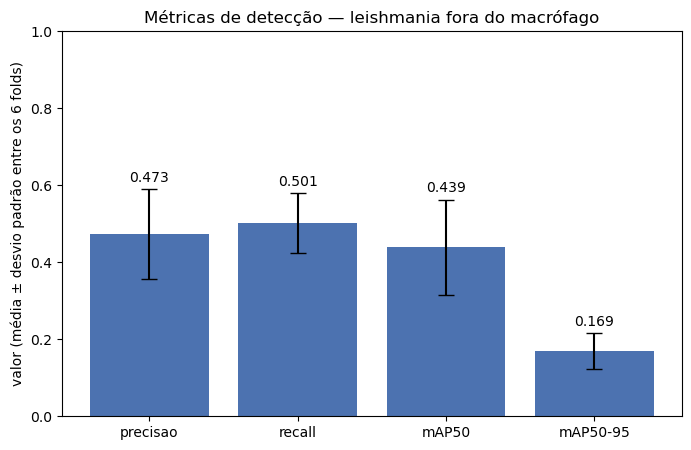

In [14]:
%matplotlib inline
fig, ax = plt.subplots(figsize=(8, 5))
metricas_plot = ['precisao', 'recall', 'mAP50', 'mAP50-95']
medias = resumo_metricas['média']
desvios = resumo_metricas['desvio_padrão']

ax.bar(metricas_plot, medias[metricas_plot], yerr=desvios[metricas_plot], capsize=6, color='#4C72B0')
ax.set_ylim(0, 1)
ax.set_ylabel('valor (média ± desvio padrão entre os 6 folds)')
ax.set_title('Métricas de detecção — leishmania fora do macrófago')
for i, m in enumerate(metricas_plot):
    ax.text(i, medias[m] + desvios[m] + 0.02, f"{medias[m]:.3f}", ha='center')
plt.show()

## Diagnóstico por lâmina (conjunto de teste)

Cada lâmina aparece no teste de 1 ou 2 folds (ver tabela de folds). Aqui o `best.pt` de cada fold é avaliado separadamente em cada lâmina de teste do fold, permitindo identificar lâminas com desempenho mais baixo.

In [15]:
linhas_metricas_lamina = []

for (n, lamina), caminho_yaml_lamina in caminhos_yaml_lamina.items():
    modelo = YOLO(caminhos_best[n])
    resultado = modelo.val(data=caminho_yaml_lamina, split='test', plots=False, verbose=False)

    metricas = extrai_metricas(resultado)
    metricas['fold'] = n
    metricas['lamina'] = lamina
    linhas_metricas_lamina.append(metricas)

df_metricas_lamina = pd.DataFrame(linhas_metricas_lamina)[['lamina', 'fold', 'precisao', 'recall', 'mAP50', 'mAP50-95']]
df_metricas_lamina.sort_values(['lamina', 'fold']).reset_index(drop=True)

Ultralytics 8.4.75 🚀 Python-3.13.9 torch-2.12.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Ti, 15842MiB)


YOLO11n summary (fused): 101 layers, 2,582,347 parameters, 0 gradients, 6.3 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4631.8±658.3 MB/s, size: 274.2 KB)


val: Scanning /mnt/arquivos/Doutorado/yolo_folds_leishmania/fold_1/labels/test_lamina/leish_3... 17 images, 11 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 17/17 5.2Kit/s 0.0s

val: New cache created: /mnt/arquivos/Doutorado/yolo_folds_leishmania/fold_1/labels/test_lamina/leish_3.cache


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 19.9it/s 0.1s

... (118 outputs left out)

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 23/23 7.5it/s 3.1s

                   all        353        992       0.38      0.436      0.325      0.131


Speed: 0.1ms preprocess, 0.5ms inference, 0.0ms loss, 0.2ms postprocess per image


,lamina,fold,precisao,recall,mAP50,mAP50-95
0,leish_1,3,0.538455,0.438015,0.434072,0.178007
1,leish_1,5,0.597889,0.237064,0.352485,0.147697
2,leish_2,2,0.371063,0.481308,0.365693,0.139103
3,leish_2,6,0.387637,0.451713,0.352008,0.134218
4,leish_3,1,0.351182,0.400000,0.255667,0.112539
5,leish_4,4,0.248457,0.195364,0.172894,0.091434
6,leish_5,1,0.525824,0.587906,0.522833,0.177579
7,leish_7,2,0.634687,0.630749,0.646519,0.257708
8,leish_7,5,0.654294,0.579063,0.611516,0.238357
9,leish_8,3,0.360612,0.461694,0.326873,0.126296


In [16]:
# Resumo por lâmina: média e desvio padrão entre as vezes em que a lâmina caiu no teste (1 ou 2 folds)
resumo_lamina = df_metricas_lamina.groupby('lamina')[['precisao', 'recall', 'mAP50', 'mAP50-95']].agg(['mean', 'std', 'count'])
resumo_lamina.round(4)

precisao                recall                 mAP50                \
            mean     std count    mean     std count    mean     std count   
lamina                                                                       
leish_1   0.5682  0.0420     2  0.3375  0.1421     2  0.3933  0.0577     2   
leish_2   0.3794  0.0117     2  0.4665  0.0209     2  0.3589  0.0097     2   
leish_3   0.3512     NaN     1  0.4000     NaN     1  0.2557     NaN     1   
leish_4   0.2485     NaN     1  0.1954     NaN     1  0.1729     NaN     1   
leish_5   0.5258     NaN     1  0.5879     NaN     1  0.5228     NaN     1   
leish_7   0.6445  0.0139     2  0.6049  0.0365     2  0.6290  0.0248     2   
leish_8   0.3704  0.0139     2  0.4491  0.0178     2  0.3261  0.0011     2   
leish_9   0.4475     NaN     1  0.5489     NaN     1  0.4418     NaN     1   

        mAP50-95                
            mean     std count  
lamina                          
leish_1   0.1629  0.0214     2  
leish_2   0.1367  0.0035     2  
leish_3   0.1125     NaN     1  
leish_4   0.0914     NaN     1  
leish_5   0.1776     NaN     1  
leish_7   0.2480  0.0137     2  
leish_8   0.1289  0.0037     2  
leish_9   0.1786     NaN     1

## Resultados visuais de detecção

Predições do fold com maior mAP50 sobre algumas imagens do seu conjunto de teste (caixas verdes = predição do modelo).

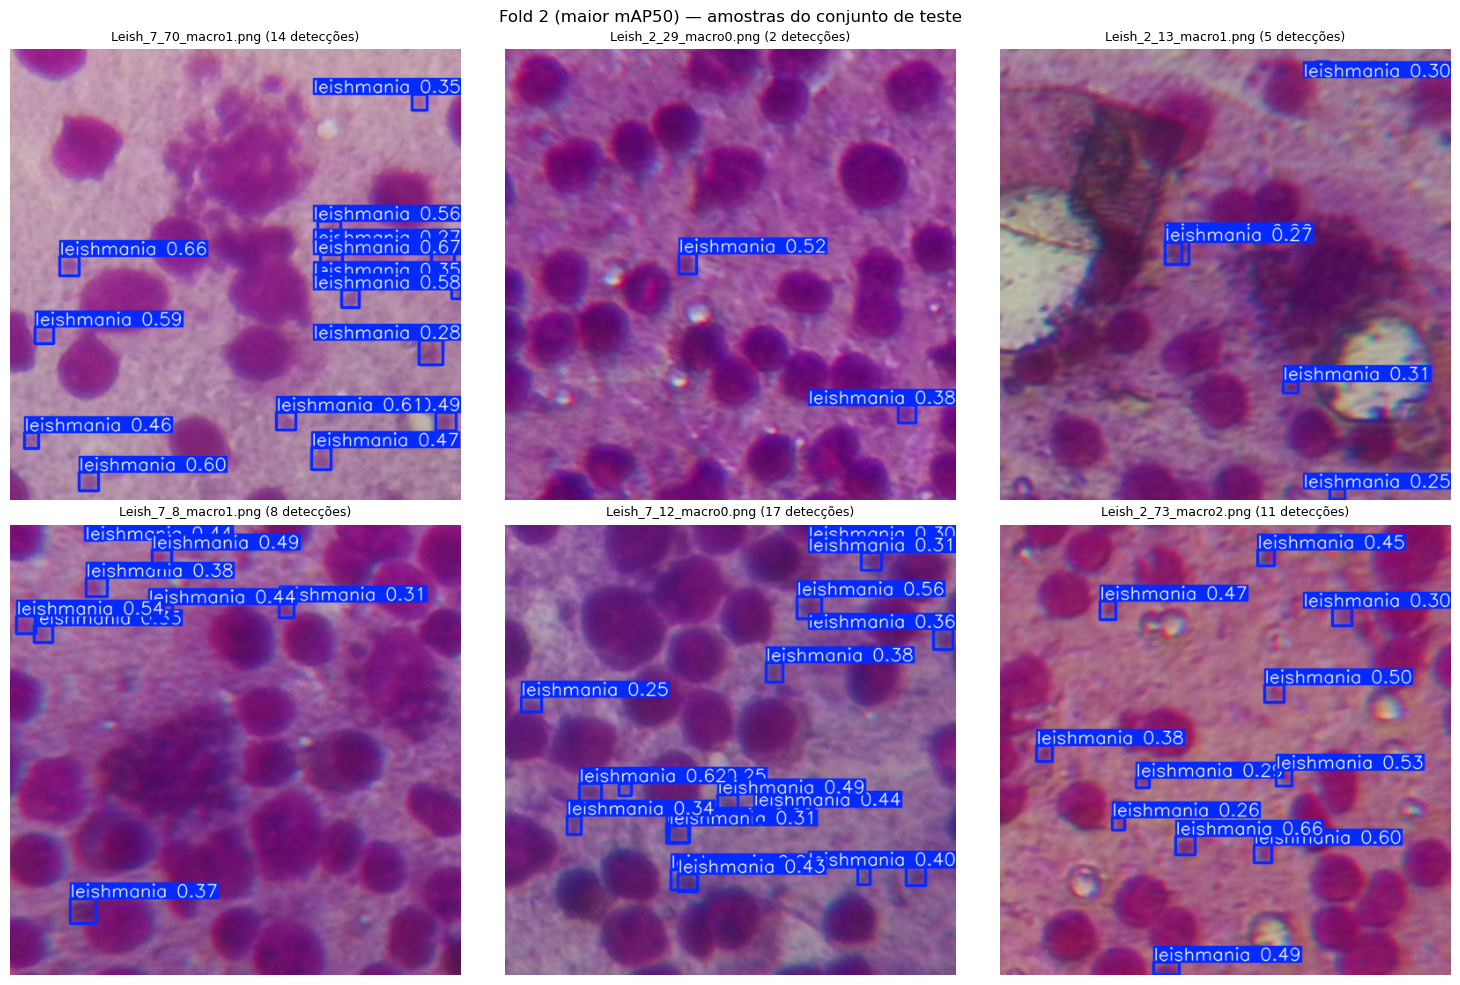

In [17]:
%matplotlib inline
fold_destaque = df_metricas_fold['mAP50'].idxmax()
modelo_destaque = YOLO(caminhos_best[fold_destaque])

pasta_teste_destaque = os.path.join(diretorio_yolo_folds, f"fold_{fold_destaque}", 'images', 'test')
imagens_teste = sorted(f for f in os.listdir(pasta_teste_destaque) if f.endswith(extensao))

random.seed(42)
n_amostras = 6
amostras = random.sample(imagens_teste, min(n_amostras, len(imagens_teste)))

fig, eixos = plt.subplots(2, 3, figsize=(15, 10))
for eixo, nome_imagem in zip(eixos.ravel(), amostras):
    caminho_imagem = os.path.join(pasta_teste_destaque, nome_imagem)
    resultado = modelo_destaque.predict(caminho_imagem, conf=0.25, verbose=False)[0]

    imagem_anotada = resultado.plot()[:, :, ::-1]  # BGR -> RGB
    eixo.imshow(imagem_anotada)
    eixo.set_title(f"{nome_imagem} ({len(resultado.boxes)} detecções)", fontsize=9)
    eixo.axis('off')

fig.suptitle(f"Fold {fold_destaque} (maior mAP50) — amostras do conjunto de teste")
plt.tight_layout()
plt.show()